# StyleVector v2 — Is the gain *personal*? Tuned steering, global control, shrinkage, multi-component & norm-preserving extension
*(LaMP_4 News Headline · LaMP_5 Scholarly Title · LaMP_7 Tweet Paraphrasing)*

## What the previous runs taught us
| Observation (from your results) | Consequence for this notebook |
|---|---|
| LaMP_7: steering works (+29 % ROUGE-L vs. base, CI clearly > 0); LaMP_4/5: no effect | The mean-difference vector may mostly encode a **task-wide style shift** ("tweet-like vs. generic LLM"), not the individual user. We now test this directly. |
| At the midterm `alpha`, relative strength $\rho=\lVert p\rVert/\lVert h\rVert$ was ≈ 0.01 (LaMP_4/5) vs. ≈ 0.47 (LaMP_7) | Strength is now parametrised by $\rho$ and **tuned on validation users**. |
| At 4× strength LaMP_7 collapses (94–100 % degenerate) for additive **and** norm-preserving steering; at the working strength $\lVert h+p\rVert/\lVert h\rVert\approx1.01$ | The collapse is *angular*, not a magnitude blow-up. Norm preservation is kept as a tested hypothesis, but not assumed to help. |
| `single_np` was significantly worse than `single_add` at equal `alpha` | Norm preservation shortens the effective push, so every method now gets **its own tuned $\rho$**. |
| `pca5_add` > `pca3_add` > `pca1_add` on LaMP_7 (small, untested) | **$k$ is tuned on validation** (not picked on test). |
| LaMP_4/5 outputs average ~23 words vs. ~10 for the gold headlines | **Output cleaning** (identical for all methods) and optional prompt suffix. |
| `EOFError` while reading the delta cache | **Atomic cache writes** + safe loaders. |

## New methods (all compared on the same test users)
| Name | Direction used for steering |
|---|---|
| `single_add` | user's mean difference $\bar\Delta_u$ — the original StyleVector |
| `single_np` | same, with norm-preserving rule |
| `global_add` | **non-personalised control**: mean difference averaged over *other* users ($g$) |
| `shrink_add` | **empirical-Bayes shrinkage**: $(1-w)\bar\Delta_u + w\,g$, $w=\kappa/(\kappa+n_u)$ — noisy small-history user means are pulled toward the global mean |
| `pca_add`, `pca_np` | top-$k$ PCA components (extension), additive / norm-preserving; $k\in$ `K_GRID` tuned |

The key scientific question this answers: **does `single_add` beat `global_add`?** If not, the gain is not personalisation.

## Protocol (leakage-free, two-stage tuning)
```
dev users --shuffle(seed)--> [ validation | test ]  (disjoint)
Stage 1 (validation): single_add over layer x rho (x position)          -> best layer/position (1-SE rule, degeneration guard)
Stage 2 (validation): every other method over rho (and k / kappa), at that layer -> best setting per method
Test: base + all methods at their own tuned setting -> paired bootstrap CIs
global vector = mean over VALIDATION users only (leave-one-out when scoring validation users) -> no test leakage
```
Selection rule: highest validation score; among configs within 1 standard error of the best, take the **smallest** $\rho$; configs with > 10 % degenerate outputs are excluded.

All numbers are raw measurements; an improvement is claimed only if the paired 95 % bootstrap CI excludes zero.

## Part 0 — Environment Setup

In [1]:
# Cell 0.1 — Working directory (local lab PC, no Drive/Kaggle mount needed)
import os
PROJECT_DIR = os.path.expanduser('~/stylevector_project')
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())

Working directory: /home/user/stylevector_project


In [2]:
# Cell 0.2 — Install dependencies
!pip install -q transformers accelerate bitsandbytes rouge-score nltk huggingface_hub --upgrade


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
# Cell 0.3 — NLTK data (with fallback if blocked)
import os
os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"
import nltk
try:
    nltk.pathsec.ALLOW_PROXIED_FETCH = True
except AttributeError:
    pass

NLTK_OK = True
try:
    nltk.download('wordnet', quiet=True)
    nltk.download('punkt', quiet=True)
    nltk.download('punkt_tab', quiet=True)
    nltk.download('omw-1.4', quiet=True)
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score
    _ = word_tokenize("test sentence")
    _ = meteor_score([["test", "sentence"]], ["test", "sentence"])
    print("NLTK data OK -- using real METEOR + real tokenizer.")
except Exception as e:
    NLTK_OK = False
    print(f"NLTK data unavailable ({e}). Falling back to unigram-F1 METEOR proxy.")

/home/user/stylevector_env/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


NLTK data OK -- using real METEOR + real tokenizer.


In [4]:
# Cell 0.4 — Imports
import json, time, re, random
from pathlib import Path

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import logging
logging.getLogger("transformers").setLevel(logging.ERROR)

plt.rcParams["figure.dpi"] = 110
RNG_SEED = 42
print("Imports OK. CUDA available:", torch.cuda.is_available())
from collections import OrderedDict
import torch.nn.functional as F

Imports OK. CUDA available: True


/home/user/stylevector_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1 — Download & Load LaMP (dev split), disjoint validation / test users

In [5]:
%%writefile download_lamp.sh
#!/usr/bin/env bash
set -euo pipefail
OUT_DIR="${1:-./data/lamp}"
BASE_URL="https://ciir.cs.umass.edu/downloads/LaMP"

declare -A TASKS=(
  [LaMP_4]="News Headline Generation"
  [LaMP_5]="Scholarly Title Generation"
  [LaMP_7]="Tweet Paraphrasing"
)
SPLITS=(train dev test)
FILE_TYPES=(questions outputs)

for task in "${!TASKS[@]}"; do
  echo "== ${task}: ${TASKS[$task]} =="
  for split in "${SPLITS[@]}"; do
    mkdir -p "${OUT_DIR}/${task}/${split}"
    for ftype in "${FILE_TYPES[@]}"; do
      url="${BASE_URL}/${task}/${split}/${split}_${ftype}.json"
      out="${OUT_DIR}/${task}/${split}/${split}_${ftype}.json"
      if [ -f "${out}" ]; then
        echo "  [cached] ${out}"
        continue
      fi
      echo "  fetching ${url}"
      if curl -sSf --retry 3 --max-time 60 -o "${out}" "${url}"; then
        echo "    saved -> ${out}"
      else
        echo "    [skip] not publicly available: ${url}"
        rm -f "${out}"
      fi
    done
  done
done
echo "Done."

Overwriting download_lamp.sh


In [6]:
# Cell 1.2 — Run the download (idempotent, safe to re-run)
!bash download_lamp.sh ./data/lamp
!ls -la ./data/lamp/LaMP_5/dev/

== LaMP_7: Tweet Paraphrasing ==
  [cached] ./data/lamp/LaMP_7/train/train_questions.json
  [cached] ./data/lamp/LaMP_7/train/train_outputs.json
  [cached] ./data/lamp/LaMP_7/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_7/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_7/test/test_questions.json
  [cached] ./data/lamp/LaMP_7/test/test_outputs.json
== LaMP_4: News Headline Generation ==
  [cached] ./data/lamp/LaMP_4/train/train_questions.json
  [cached] ./data/lamp/LaMP_4/train/train_outputs.json
  [cached] ./data/lamp/LaMP_4/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_4/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_4/test/test_questions.json
  [cached] ./data/lamp/LaMP_4/test/test_outputs.json
== LaMP_5: Scholarly Title Generation ==
  [cached] ./data/lamp/LaMP_5/train/train_questions.json
  [cached] ./data/lamp/LaMP_5/train/train_outputs.json
  [cached] ./data/lamp/LaMP_5/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_5/dev/dev_outputs.json
  [cached] ./data/lamp/

In [7]:
%%writefile load_lamp_data.py
import json
from pathlib import Path
from typing import Optional

TASK_PROFILE_FIELDS = {
    "LaMP_4": ("text", "title"),
    "LaMP_5": ("abstract", "title"),
    "LaMP_7": (None, "text"),
}


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def build_gold_lookup(outputs_json: dict) -> dict:
    return {item["id"]: item["output"] for item in outputs_json["golds"]}


def make_synthetic_input(y_text: str) -> str:
    return "Write a short tweet."


def load_task_split(data_dir: Path, task: str, split: str,
                     max_users: Optional[int] = None,
                     max_history_per_user: Optional[int] = None,
                     min_history_len: int = 3):
    assert task in TASK_PROFILE_FIELDS, f"Unsupported/unmapped task: {task}"
    input_field, output_field = TASK_PROFILE_FIELDS[task]

    q_path = data_dir / task / split / f"{split}_questions.json"
    o_path = data_dir / task / split / f"{split}_outputs.json"

    questions = load_json(q_path)
    gold_lookup = {}
    if o_path.exists():
        gold_lookup = build_gold_lookup(load_json(o_path))

    for q in questions:
        if q["profile"]:
            sample = q["profile"][0]
            print(f"[{task}/{split}] sample profile item keys: {list(sample.keys())}")
            if output_field not in sample:
                raise KeyError(f"Expected output field '{output_field}' not found in {sample}")
            break

    users = {}
    for q in questions:
        user_id = q["id"]
        history = []
        for item in q["profile"]:
            y_i = item.get(output_field)
            if y_i is None:
                continue
            x_i = item.get(input_field) if input_field is not None else make_synthetic_input(y_i)
            history.append((x_i, y_i))

        if len(history) < min_history_len:
            continue
        if max_history_per_user is not None:
            history = history[:max_history_per_user]

        gold = gold_lookup.get(user_id)
        if gold is None:
            continue

        users[user_id] = {"history": history, "query_input": q["input"], "query_gold": gold}
        if max_users is not None and len(users) >= max_users:
            break

    return users

Overwriting load_lamp_data.py


In [8]:
# Cell 1.4 — Load all 3 tasks, per-task history cap, DISJOINT validation / test split
from load_lamp_data import load_task_split
from pathlib import Path

TASKS = ["LaMP_4", "LaMP_5", "LaMP_7"]
DATA_DIR = Path("./data/lamp")

MAX_HISTORY_PER_USER_BY_TASK = {"LaMP_4": 30, "LaMP_5": 30, "LaMP_7": 15}   # more history = less noisy user mean

N_VAL_USERS  = 40     # users per task for tuning AND for the global vector
N_TEST_USERS = 150    # users per task for the final evaluation

val_users, test_users = {}, {}
for task in TASKS:
    cap = MAX_HISTORY_PER_USER_BY_TASK[task]
    pool = load_task_split(
        data_dir=DATA_DIR, task=task, split="dev",
        max_users=None, max_history_per_user=cap, min_history_len=3,
    )
    all_ids = list(pool.keys())
    random.Random(RNG_SEED).shuffle(all_ids)

    val_ids  = all_ids[:N_VAL_USERS]
    test_ids = all_ids[N_VAL_USERS:N_VAL_USERS + N_TEST_USERS]
    assert not set(val_ids) & set(test_ids)
    val_users[task]  = {uid: pool[uid] for uid in val_ids}
    test_users[task] = {uid: pool[uid] for uid in test_ids}

    avg_hist = np.mean([len(u["history"]) for u in test_users[task].values()])
    print(f"{task}: pool={len(pool)}, val={len(val_users[task])}, test={len(test_users[task])}, "
          f"history_cap={cap}, avg_actual_history={avg_hist:.1f}")

[LaMP_4/dev] sample profile item keys: ['text', 'title', 'id']
LaMP_4: pool=1925, val=40, test=150, history_cap=30, avg_actual_history=24.9
[LaMP_5/dev] sample profile item keys: ['title', 'abstract', 'id']
LaMP_5: pool=2500, val=40, test=150, history_cap=30, avg_actual_history=30.0
[LaMP_7/dev] sample profile item keys: ['text', 'id']
LaMP_7: pool=1500, val=40, test=150, history_cap=15, avg_actual_history=12.7


## Part 2 — Load LLaMA-2-7B-chat (4-bit)

Requires a HuggingFace token with approved access to `meta-llama/Llama-2-7b-chat-hf`.

In [9]:
# Cell 2.1 — Clean up any stale GPU memory from a previous session first
import gc, torch
for var_name in ["model", "tokenizer"]:
    if var_name in dir():
        del globals()[var_name]
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")
    print(f"GPU memory reserved:  {torch.cuda.memory_reserved()/1e9:.2f} GB")

GPU memory allocated: 0.00 GB
GPU memory reserved:  0.00 GB


In [10]:
# Cell 2.2 — Load tokenizer + model (4-bit NF4 -- see Part 0 note on why)
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL_NAME = "meta-llama/Llama-2-7b-chat-hf"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
)
# To match the paper's exact 8-bit setup instead (needs a GPU with more
# headroom, e.g. 16GB+), comment out the block above and use:
#   quant_config = BitsAndBytesConfig(load_in_8bit=True)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="auto",
    quantization_config=quant_config,
)
model.eval()
model.generation_config.max_length = 1024  # avoid huge KV-cache pre-allocation on tight VRAM

N_LAYERS = len(model.model.layers)
HIDDEN_DIM = model.config.hidden_size
print(f"Loaded {MODEL_NAME}")
print(f"Layers: {N_LAYERS} | Hidden dim: {HIDDEN_DIM}")
print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

Could not reach the Hub ([Errno 101] Network is unreachable). Using cached commit hash for 'meta-llama/Llama-2-7b-chat-hf'.
Could not reach the Hub ([Errno 101] Network is unreachable). Using cached commit hash for 'meta-llama/Llama-2-7b-chat-hf'.
Loading weights: 100%|██████████| 291/291 [00:14<00:00, 20.53it/s]


Loaded meta-llama/Llama-2-7b-chat-hf
Layers: 32 | Hidden dim: 4096
GPU memory allocated: 4.19 GB


In [11]:
# Cell 2.3 — Prompt formatting (chat template, [INST] fallback)
def build_input_ids(tokenizer, prompt, device):
    messages = [{"role": "user", "content": prompt}]
    try:
        inputs = tokenizer.apply_chat_template(
            messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
        )
        return inputs["input_ids"].to(device)
    except Exception:
        formatted = f"<s>[INST] {prompt} [/INST]"
        return tokenizer(formatted, return_tensors="pt").input_ids.to(device)

_test = build_input_ids(tokenizer, "Say hello.", model.device)
print("Prompt formatting OK, input shape:", _test.shape)

Prompt formatting OK, input shape: torch.Size([1, 11])


In [12]:
# Cell 2.4 — [OPTIONAL] stronger generic-response model M_g
# Default None = LLaMA-2 itself. Example: GENERIC_MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"  (~4-5 GB extra in 4-bit)
GENERIC_MODEL_ID = None

gen_model = gen_tok = None
if GENERIC_MODEL_ID:
    gen_tok = AutoTokenizer.from_pretrained(GENERIC_MODEL_ID)
    gen_model = AutoModelForCausalLM.from_pretrained(
        GENERIC_MODEL_ID, torch_dtype=torch.float16, device_map="auto", quantization_config=quant_config)
    gen_model.eval()
DELTA_TAG = "self" if not GENERIC_MODEL_ID else re.sub(r"[^A-Za-z0-9]+", "_", GENERIC_MODEL_ID)
print("Generic-response model:", GENERIC_MODEL_ID or "LLaMA-2 itself", "| cache tag:", DELTA_TAG)

Generic-response model: LLaMA-2 itself | cache tag: self


## Part 3 — Core machinery
3.1 prompts · 3.2 output cleaner · 3.3 generation · 3.4 activations · 3.5 cached contrastive deltas ·
3.6 style directions (user / global / shrinkage / PCA) · 3.7 steering hook · 3.8 self-test · 3.9 metrics · 3.10 degeneration check

In [13]:
# Cell 3.1 — Task prompts (exact wording from the paper's Appendix E)
TASK_PROMPTS = {
    "LaMP_4": lambda text: f'Generate a headline for the following article "{text}".',
    "LaMP_5": lambda text: f'Generate a title for the following abstract of a paper "{text}".',
    "LaMP_7": lambda text: f'Paraphrase the following tweet without any explanation before or after it "{text}".',
}

# Optional suffix appended to EVERY task prompt (for generic responses and for steered/unsteered generation alike).
# Default "" = the paper's exact prompts. Example to curb chatty answers:
#   PROMPT_SUFFIX = " Output only the result on a single line, with no explanation."
# NOTE: changing it changes y_hat, so it is part of the delta-cache key (see Cell 4.2).
PROMPT_SUFFIX = ""
_BASE_PROMPTS = dict(TASK_PROMPTS)
TASK_PROMPTS = {t: (lambda f: (lambda x: f(x) + PROMPT_SUFFIX))(fn) for t, fn in _BASE_PROMPTS.items()}

In [14]:
# Cell 3.2 — Output cleaner (identical for ALL methods incl. the baseline)
CLEAN_GENERIC = True     # clean the style-agnostic responses y_hat before extracting activations
CLEAN_PREDS   = True     # clean final predictions before scoring (raw scores are stored too)

_LEAD = r"^(sure|certainly|of course|absolutely|okay|ok|here)\b"

def clean_output(text):
    t = (text or "").strip()
    lines = [l.strip() for l in t.split("\n") if l.strip()]
    if len(lines) > 1 and re.match(_LEAD, lines[0], re.I) and re.search(r"[:!]\s*$", lines[0]):
        lines = lines[1:]
    if not lines:
        return ""
    t = lines[0]
    t = re.sub(r"^(sure|certainly|of course|absolutely)[!,.]?\s*", "", t, flags=re.I)
    t = re.sub(r"^here('s| is| are)\b[^:\n]{0,80}:\s*", "", t, flags=re.I)
    return t.strip().strip("\"'\u201c\u201d\u2018\u2019*` ").strip()

assert clean_output('Sure! Here is a headline: "Teens Online: Tips for Parents"') == "Teens Online: Tips for Parents"
assert clean_output("Sure! Here's a title:\n\nDeep Nets for Vision\n\nI hope this helps!") == "Deep Nets for Vision"
assert clean_output("  Plain answer  ") == "Plain answer"
print("clean_output OK")

clean_output OK


In [15]:
# Cell 3.3 — Generation from pre-tokenised prompt ids, optionally steered
#   h' = h + rho*||h||*d                       (norm_preserve=False)
#   h' = ||h|| * (h + rho*||h||*d)/||...||      (norm_preserve=True)
def generate_from_ids(input_ids, max_new_tokens=40, layer_idx=None, direction=None,
                      rho=0.0, norm_preserve=False, positions="last"):
    handle = None
    if direction is not None:
        handle = model.model.layers[layer_idx].register_forward_hook(
            make_steering_hook(direction, rho, norm_preserve, positions))
    try:
        with torch.no_grad():
            out = model.generate(input_ids, max_new_tokens=max_new_tokens,
                                 do_sample=False, pad_token_id=tokenizer.eos_token_id)
    finally:
        if handle is not None:
            handle.remove()
    return tokenizer.decode(out[0][input_ids.shape[1]:], skip_special_tokens=True).strip()

def generic_generate(prompt, max_new_tokens=40):
    if gen_model is None:
        return generate_from_ids(build_input_ids(tokenizer, prompt, model.device), max_new_tokens)
    ids = gen_tok.apply_chat_template([{"role": "user", "content": prompt}],
                                      add_generation_prompt=True, return_tensors="pt",
                                      return_dict=True)["input_ids"].to(gen_model.device)
    with torch.no_grad():
        out = gen_model.generate(ids, max_new_tokens=max_new_tokens, do_sample=False,
                                 pad_token_id=gen_tok.eos_token_id)
    return gen_tok.decode(out[0][ids.shape[1]:], skip_special_tokens=True).strip()

In [16]:
# Cell 3.4 — Last-token activations at SEVERAL layers in one forward pass (paper Eq. 5)
def get_last_token_activations(model, tokenizer, text, layer_idxs, max_len=512):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=max_len).to(model.device)
    captured, handles = {}, []
    def make_hook(L):
        def hook(module, inp, output):
            hs = output[0] if isinstance(output, tuple) else output
            captured[L] = hs[:, -1, :].detach().float().cpu().squeeze(0)
        return hook
    for L in layer_idxs:
        handles.append(model.model.layers[L].register_forward_hook(make_hook(L)))
    try:
        with torch.no_grad():
            model(**inputs)
    finally:
        for h in handles:
            h.remove()
    return captured

In [17]:
# Cell 3.5 — Contrastive deltas for several layers at once, cached on disk.
# Writes are ATOMIC (temp file + rename) so an interrupted run can never leave a half-written .pt file,
# and loading is SAFE (a damaged file is deleted and recomputed instead of crashing the notebook).
def compute_user_deltas_multi(history, task, layer_idxs, max_history, max_gen_tokens):
    prompt_fn = TASK_PROMPTS[task]
    per_layer = {L: [] for L in layer_idxs}
    y_hats = []
    for x_i, y_i in history[:max_history]:
        if not x_i or not y_i:
            continue
        raw = generic_generate(prompt_fn(x_i), max_new_tokens=max_gen_tokens)
        y_hat = clean_output(raw) if CLEAN_GENERIC else raw
        if not y_hat:
            y_hat = raw
        a_p = get_last_token_activations(model, tokenizer, f"{x_i} {y_i}", layer_idxs)
        a_n = get_last_token_activations(model, tokenizer, f"{x_i} {y_hat}", layer_idxs)
        for L in layer_idxs:
            per_layer[L].append(a_p[L] - a_n[L])
        y_hats.append(y_hat)
    if not y_hats:
        return None, None
    return {L: torch.stack(v) for L, v in per_layer.items()}, y_hats

def delta_cache_path(task, uid):
    cap = MAX_HISTORY_PER_USER_BY_TASK[task]
    return DELTA_DIR / f"{task}_h{cap}_{str(uid).replace('/', '_')}.pt"

def safe_load_deltas(path):
    """Returns {layer: (n, d) float tensor} or None if the file is missing/damaged."""
    try:
        blob = torch.load(path, map_location="cpu")
        return {L: t.float() for L, t in blob["deltas"].items()}
    except Exception:
        return None

def atomic_torch_save(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

def get_or_compute_deltas(task, uid, history, max_history, max_gen_tokens):
    path = delta_cache_path(task, uid)
    if path.exists():
        d = safe_load_deltas(path)
        if d is not None:
            return d
        path.unlink()                                       # damaged -> recompute
    deltas, y_hats = compute_user_deltas_multi(history, task, DELTA_LAYERS, max_history, max_gen_tokens)
    if deltas is None:
        return None
    atomic_torch_save({"deltas": {L: t.half() for L, t in deltas.items()}, "y_hat": y_hats}, path)
    return {L: t.float() for L, t in deltas.items()}

In [18]:
# Cell 3.6 — Style directions: user mean (original) | global mean (control) | shrinkage | top-k PCA (extension)
def style_components(deltas, k):
    """Top-k PCA components of {D_i} U {-D_i} (paper Eq. 10, generalised to k>1).
    V (k_eff, d): unit-norm, orthogonal, sign-aligned with the mean difference.
    lam (k_eff,): eigenvalues of sum_i D_i D_i^T + (-D_i)(-D_i)^T = 2 D^T D."""
    D = deltas.float()
    mean_vec = D.mean(0)
    _, S, Vh = torch.linalg.svd(D, full_matrices=False)
    k_eff = min(k, Vh.shape[0])
    V, lam = Vh[:k_eff], 2.0 * S[:k_eff] ** 2
    proj = V @ mean_vec
    sign = torch.where(proj >= 0, torch.ones_like(proj), -torch.ones_like(proj))
    return V * sign[:, None], lam

def _unit(v):
    n = v.norm()
    return v / n if n > 0 else v

def build_direction(deltas, method, k=1, global_mean=None, kappa=10.0):
    """UNIT-norm steering direction.
       'mean'  : user mean difference
       'global': mean over other users (non-personalised control)        needs global_mean
       'shrink': (1-w) * user_mean + w * global_mean,  w = kappa/(kappa+n)   needs global_mean
       'pca'   : sum_j w_j v_j,  w_j ~ sqrt(lambda_j), ||w||=1 (the v_j are orthonormal)"""
    D = deltas.float()
    mean_vec = D.mean(0)
    if method == "mean":
        return _unit(mean_vec)
    if method == "global":
        return _unit(global_mean.float())
    if method == "shrink":
        w = kappa / (kappa + D.shape[0])
        return _unit((1.0 - w) * mean_vec + w * global_mean.float())
    V, lam = style_components(D, k)
    w = lam.sqrt()
    if w.norm() == 0:
        return torch.zeros_like(mean_vec)
    w = w / w.norm()
    return _unit((w[:, None] * V).sum(0))

In [19]:
# Cell 3.7 — Steering hook: relative strength rho, optional token positions
def make_steering_hook(direction, rho, norm_preserve=False, positions="last"):
    direction = direction.clone().float()
    def hook(module, inp, output):
        is_tuple = isinstance(output, tuple)
        hs = output[0] if is_tuple else output
        hs = hs.clone()
        if positions == "all" and hs.shape[1] > 2:
            sl = slice(1, None)             # prefill: all prompt tokens except BOS (abnormally large norm)
        else:
            sl = slice(-1, None)            # last prompt token during prefill, and every generated token
        h = hs[:, sl, :].float()
        hn = h.norm(dim=-1, keepdim=True)
        new = h + rho * hn * direction.to(hs.device)
        if norm_preserve:
            new = new * (hn / new.norm(dim=-1, keepdim=True).clamp_min(1e-6))
        hs[:, sl, :] = new.to(hs.dtype)
        return (hs,) + tuple(output[1:]) if is_tuple else hs
    return hook

In [20]:
# Cell 3.8 — Self-test of the maths (no model / GPU needed)
import torch.nn as nn
torch.manual_seed(0)
D = torch.randn(12, 64) + 2.0 * torch.randn(1, 64)
g = torch.randn(64)

V, lam = style_components(D, 5)
assert torch.allclose(V @ V.T, torch.eye(5), atol=1e-4)
assert (V @ D.mean(0) >= 0).all() and (lam[:-1] >= lam[1:]).all()
M = sum(torch.outer(d, d) + torch.outer(-d, -d) for d in D)
assert torch.allclose(torch.linalg.eigvalsh(M).flip(0)[:5], lam, rtol=1e-3)
for meth, k in [("mean", 1), ("pca", 1), ("pca", 3), ("pca", 5)]:
    assert abs(build_direction(D, meth, k).norm().item() - 1.0) < 1e-4
assert torch.nn.functional.cosine_similarity(build_direction(D, "pca", 1), D.mean(0), dim=0) > 0

# global / shrinkage directions
assert torch.allclose(build_direction(D, "global", 1, global_mean=g), g / g.norm(), atol=1e-5)
assert torch.allclose(build_direction(D, "shrink", 1, global_mean=D.mean(0), kappa=10), build_direction(D, "mean"), atol=1e-5)
w = 10 / (10 + D.shape[0]); expect = (1 - w) * D.mean(0) + w * g
assert torch.allclose(build_direction(D, "shrink", 1, global_mean=g, kappa=10), expect / expect.norm(), atol=1e-5)

class _Dummy(nn.Module):
    def forward(self, x): return (x,)
layer, h, d = _Dummy(), torch.randn(2, 6, 64) * 3, build_direction(D, "pca", 3)
def run(**kw):
    hd = layer.register_forward_hook(make_steering_hook(d, **kw)); out = layer(h)[0]; hd.remove(); return out

o = run(rho=0.3)
assert torch.allclose((o[:, -1] - h[:, -1]).norm(dim=-1), 0.3 * h[:, -1].norm(dim=-1), atol=1e-4)
assert torch.equal(o[:, :-1], h[:, :-1])
o = run(rho=0.3, norm_preserve=True)
assert torch.allclose(o[:, -1].norm(dim=-1), h[:, -1].norm(dim=-1), atol=1e-4)
o = run(rho=0.3, positions="all")
assert torch.equal(o[:, 0], h[:, 0]) and not torch.allclose(o[:, 1:], h[:, 1:])
h1 = torch.randn(2, 1, 64); hd = layer.register_forward_hook(make_steering_hook(d, 0.3, False, "all"))
assert not torch.allclose(layer(h1)[0], h1); hd.remove()

# atomic save / safe load round-trip, and damaged-file handling
import tempfile
_p = Path(tempfile.mkdtemp()) / "x.pt"
atomic_torch_save({"deltas": {16: torch.randn(3, 8).half()}}, _p)
assert safe_load_deltas(_p)[16].shape == (3, 8)
_p.write_bytes(b"")                                           # simulate an interrupted write
assert safe_load_deltas(_p) is None
print("All self-tests passed.")

All self-tests passed.


/tmp/ipykernel_163691/4181944788.py:31: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  blob = torch.load(path, map_location="cpu")


In [21]:
# Cell 3.6 — Evaluation metrics
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

def _simple_tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

def _simple_meteor_proxy(pred_tokens, gold_tokens):
    if not pred_tokens or not gold_tokens:
        return 0.0
    matches = sum(1 for t in pred_tokens if t in gold_tokens)
    precision = matches / len(pred_tokens)
    recall = matches / len(gold_tokens)
    if precision + recall == 0:
        return 0.0
    return (2 * precision * recall) / (precision + recall)

if NLTK_OK:
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score as _real_meteor

def score_pair(pred, gold):
    rouge_l = scorer.score(gold, pred)['rougeL'].fmeasure
    if NLTK_OK:
        meteor = _real_meteor([word_tokenize(gold)], word_tokenize(pred))
    else:
        meteor = _simple_meteor_proxy(_simple_tokenize(pred), _simple_tokenize(gold))
    return rouge_l, meteor

print("Metric functions ready. Using", "REAL METEOR" if NLTK_OK else "FALLBACK METEOR proxy")

Metric functions ready. Using REAL METEOR


In [22]:
# Cell 3.10 — Degeneration check (empty output, or heavily repeated tokens)
def is_degenerate(text):
    toks = re.findall(r"\w+|[^\w\s]", (text or "").lower())
    if len(toks) == 0:
        return True
    return len(toks) >= 8 and len(set(toks)) / len(toks) < 0.4

## Part 4 — Configuration, checkpoints, global vector, experiment runner

In [23]:
# Cell 4.1 — Settings
MAX_GEN_TOKENS_PER_TASK = {"LaMP_4": 40, "LaMP_5": 40, "LaMP_7": 40}

LAYER_GRID  = [12, 16, 20, 24]            # stage 1: layers searched (single_add)
RHO_GRID    = [0.05, 0.1, 0.2, 0.4, 0.8]  # perturbation size as a fraction of ||h|| (extend if the best is at an edge)
POS_GRID    = ["last"]                    # add "all" to also search steering on all prompt tokens
K_GRID      = [3, 5]                      # PCA components tried (tuned on validation)
KAPPA_GRID  = [10]                        # shrinkage strength: w = kappa/(kappa+n); try [10, 40] for a wider search
USE_1SE         = True                    # among configs within 1 SE of the best, prefer the smallest rho
MAX_DEGENERATE  = 0.10                    # exclude configs whose validation outputs are > 10% degenerate
DELTA_LAYERS = sorted(set(LAYER_GRID) | {8, 28})

# method families: name -> how the direction is built and whether the update is norm-preserving
FAMILIES = OrderedDict([
    ("single_add", dict(method="mean",   norm=False)),   # original StyleVector
    ("single_np",  dict(method="mean",   norm=True)),
    ("global_add", dict(method="global", norm=False)),   # non-personalised control
    ("shrink_add", dict(method="shrink", norm=False)),   # shrink user mean toward global mean
    ("pca_add",    dict(method="pca",    norm=False)),   # extension: multi-component
    ("pca_np",     dict(method="pca",    norm=True)),    # extension: multi-component + norm-preserving (our full method)
])
BASE_SV, FULL_NAME = "single_add", "pca_np"
print("layers", LAYER_GRID, "| rho", RHO_GRID, "| k", K_GRID, "| kappa", KAPPA_GRID, "| families", list(FAMILIES))

layers [12, 16, 20, 24] | rho [0.05, 0.1, 0.2, 0.4, 0.8] | k [3, 5] | kappa [10] | families ['single_add', 'single_np', 'global_add', 'shrink_add', 'pca_add', 'pca_np']


In [24]:
# Cell 4.2 — Directories. The delta cache key covers: generic model, cleaning flag, prompt suffix, history cap.
import hashlib
CHECKPOINT_DIR = Path("./checkpoints_v2")
CHECKPOINT_DIR.mkdir(exist_ok=True)
_sfx = hashlib.md5(PROMPT_SUFFIX.encode()).hexdigest()[:6]
DELTA_DIR = CHECKPOINT_DIR / f"deltas_{DELTA_TAG}_clean{int(CLEAN_GENERIC)}_sfx{_sfx}"
DELTA_DIR.mkdir(exist_ok=True)
for stale in DELTA_DIR.glob("*.tmp"):                       # leftovers of an interrupted atomic write
    stale.unlink()
with open(CHECKPOINT_DIR / "settings.json", "w") as f:
    json.dump({"MAX_HISTORY": MAX_HISTORY_PER_USER_BY_TASK, "N_VAL": N_VAL_USERS, "N_TEST": N_TEST_USERS,
               "LAYER_GRID": LAYER_GRID, "RHO_GRID": RHO_GRID, "POS_GRID": POS_GRID, "K_GRID": K_GRID,
               "KAPPA_GRID": KAPPA_GRID, "GENERIC_MODEL_ID": GENERIC_MODEL_ID, "CLEAN_GENERIC": CLEAN_GENERIC,
               "CLEAN_PREDS": CLEAN_PREDS, "PROMPT_SUFFIX": PROMPT_SUFFIX}, f, indent=2)
print("Results directory:", CHECKPOINT_DIR.resolve(), "| delta cache:", DELTA_DIR.name)

Results directory: /home/user/stylevector_project/checkpoints_v2 | delta cache: deltas_self_clean1_sfxd41d8c


In [25]:
# Cell 4.3 — Checkpoint helpers (resumable JSONL; robust to files damaged by an interrupted write)
def checkpoint_path(tag, task):
    return CHECKPOINT_DIR / f"{tag}_{task}.jsonl"

def _iter_records(text):
    dec, i = json.JSONDecoder(), 0
    while True:
        j = text.find("{", i)
        if j < 0:
            return
        try:
            obj, end = dec.raw_decode(text, j)
        except json.JSONDecodeError:
            i = j + 1
            continue
        if isinstance(obj, dict) and "user_id" in obj and "preds" in obj:
            yield obj
        i = end

def load_checkpoint(tag, task):
    path, done = checkpoint_path(tag, task), {}
    if not path.exists():
        return done
    text = path.read_text(errors="ignore")
    n_lines = sum(1 for l in text.splitlines() if l.strip())
    for row in _iter_records(text):
        done[row["user_id"]] = row
    if len(done) != n_lines:
        backup = path.with_suffix(".jsonl.bak")
        path.rename(backup)
        with open(path, "w") as f:
            for row in done.values():
                f.write(json.dumps(row) + "\n")
        print(f"[{path.name}] {n_lines} lines on disk -> {len(done)} valid records recovered; original kept as {backup.name}")
    return done

def append_checkpoint(tag, task, row):
    with open(checkpoint_path(tag, task), "a") as f:
        f.write(json.dumps(row) + "\n")
        f.flush()

In [26]:
# Cell 4.4 — Global style vector (mean over VALIDATION users only) and config builders
GLOBAL, USER_MEAN = {}, {}

def build_global(task):
    """Sum of per-user mean deltas over the validation users, for every cached layer.
    Test users are never included -> no leakage. Validation users use leave-one-out (see global_mean_for)."""
    cap, max_gen = MAX_HISTORY_PER_USER_BY_TASK[task], MAX_GEN_TOKENS_PER_TASK[task]
    sums, n = {L: None for L in DELTA_LAYERS}, 0
    USER_MEAN[task] = {}
    for uid, u in tqdm(val_users[task].items(), desc=f"global/{task}"):
        d = get_or_compute_deltas(task, uid, u["history"], cap, max_gen)
        if d is None:
            continue
        USER_MEAN[task][uid] = {L: d[L].mean(0) for L in DELTA_LAYERS}
        for L in DELTA_LAYERS:
            m = USER_MEAN[task][uid][L]
            sums[L] = m.clone() if sums[L] is None else sums[L] + m
        n += 1
    GLOBAL[task] = {L: (sums[L], n) for L in DELTA_LAYERS}
    print(f"{task}: global vector built from {n} validation users")

def global_mean_for(task, layer, uid):
    S, N = GLOBAL[task][layer]
    if uid in USER_MEAN[task] and N > 1:                    # validation user -> leave-one-out
        return (S - USER_MEAN[task][uid][layer]) / (N - 1)
    return S / N

def make_spec(family, layer, rho, pos="last", k=1, kappa=0.0):
    f = FAMILIES[family]
    return dict(family=family, method=f["method"], norm=f["norm"], k=int(k), kappa=float(kappa),
                layer=int(layer), rho=float(rho), pos=str(pos))

def stage1_configs():
    """Stage 1: original method over layer x rho x position."""
    cfgs = OrderedDict(base=None)
    for L in LAYER_GRID:
        for r in RHO_GRID:
            for pos in POS_GRID:
                cfgs[f"single_add|L{L}|r{r:g}|{pos}"] = make_spec("single_add", L, r, pos)
    return cfgs

def stage2_configs(layer, pos):
    """Stage 2: all other families over rho (and k / kappa) at the stage-1 layer/position."""
    cfgs = OrderedDict(base=None)
    for fam in FAMILIES:
        if fam == "single_add":
            continue
        ks     = K_GRID     if FAMILIES[fam]["method"] == "pca"    else [1]
        kappas = KAPPA_GRID if FAMILIES[fam]["method"] == "shrink" else [0.0]
        for k in ks:
            for kap in kappas:
                for r in RHO_GRID:
                    cfgs[f"{fam}|k{k}|kap{kap:g}|L{layer}|r{r:g}|{pos}"] = make_spec(fam, layer, r, pos, k, kap)
    return cfgs

_n1 = len(stage1_configs()) - 1
_n2 = len(stage2_configs(LAYER_GRID[0], POS_GRID[0])) - 1
print(f"stage 1: {_n1} steered configs / val user | stage 2: {_n2} steered configs / val user")

stage 1: 20 steered configs / val user | stage 2: 35 steered configs / val user


In [27]:
# Cell 4.5 — Experiment runner (resumable). Raw outputs stored; scores on cleaned AND raw outputs.
def run_experiment(tag, task, users, configs, verbose_every=0):
    max_gen = MAX_GEN_TOKENS_PER_TASK[task]
    cap = MAX_HISTORY_PER_USER_BY_TASK[task]
    prompt_fn = TASK_PROMPTS[task]
    if any(sp and sp["method"] in ("global", "shrink") for sp in configs.values()) and task not in GLOBAL:
        build_global(task)
    done = load_checkpoint(tag, task)

    n_new = 0
    for i, uid in enumerate(tqdm(list(users), desc=f"{tag}/{task}")):
        if uid in done:
            continue
        u = users[uid]
        try:
            deltas = get_or_compute_deltas(task, uid, u["history"], cap, max_gen)
            if deltas is None:
                continue
            gold = u["query_gold"]
            input_ids = build_input_ids(tokenizer, prompt_fn(u["query_input"]), model.device)

            dirs, raw, specs = {}, {}, {}
            for name, sp in configs.items():
                if sp is None:
                    raw[name], specs[name] = generate_from_ids(input_ids, max_gen), None
                    continue
                key = (sp["layer"], sp["method"], sp["k"], sp["kappa"])
                if key not in dirs:
                    gm = global_mean_for(task, sp["layer"], uid) if sp["method"] in ("global", "shrink") else None
                    dirs[key] = build_direction(deltas[sp["layer"]], sp["method"], sp["k"], gm, sp["kappa"])
                raw[name] = generate_from_ids(input_ids, max_gen, sp["layer"], dirs[key],
                                              sp["rho"], sp["norm"], sp["pos"])
                specs[name] = sp
            preds = {n: (clean_output(t) if CLEAN_PREDS else t) for n, t in raw.items()}

            rl, mt, rl_raw, mt_raw = {}, {}, {}, {}
            for n in preds:
                rl[n], mt[n] = score_pair(preds[n], gold)
                rl_raw[n], mt_raw[n] = score_pair(raw[n], gold)

            append_checkpoint(tag, task, {"user_id": uid, "task": task, "gold": gold, "raw": raw,
                                          "preds": preds, "specs": specs, "rougeL": rl, "meteor": mt,
                                          "rougeL_raw": rl_raw, "meteor_raw": mt_raw})
            n_new += 1
            if verbose_every and (i % verbose_every == 0):
                tqdm.write(f"[{uid}] gold: {gold[:60]!r}")
                for n in list(preds)[:3]:
                    tqdm.write(f"   {n[:34]:<34}: {preds[n][:60]!r}")
        except Exception as e:
            tqdm.write(f"[{uid}] ERROR, skipping: {e}")
    print(f"{tag}/{task}: {n_new} new users this run ({len(load_checkpoint(tag, task))} total).")

In [28]:
# Cell 4.6 — Loading results + selection logic (1-SE rule, degeneration guard)
def load_long(tag, tasks):
    recs = []
    for task in tasks:
        for row in load_checkpoint(tag, task).values():
            for name, pred in row["preds"].items():
                sp = row["specs"][name]
                recs.append(dict(
                    task=task, user_id=row["user_id"], config=name, pred=pred, raw=row["raw"][name], gold=row["gold"],
                    rougeL=row["rougeL"][name], meteor=row["meteor"][name],
                    rougeL_raw=row.get("rougeL_raw", {}).get(name, np.nan),
                    meteor_raw=row.get("meteor_raw", {}).get(name, np.nan),
                    family=sp["family"] if sp else "base", method=sp["method"] if sp else "base",
                    k=sp["k"] if sp else 0, kappa=sp["kappa"] if sp else 0.0,
                    norm=bool(sp["norm"]) if sp else False, rho=sp["rho"] if sp else 0.0,
                    layer=sp["layer"] if sp else None, pos=sp["pos"] if sp else "-"))
    df = pd.DataFrame(recs)
    if len(df):
        df["score"] = (df["rougeL"] + df["meteor"]) / 2
        df["degenerate"] = df["pred"].map(is_degenerate)
    return df

def pick_best(sub, key_cols):
    """sub: per-user rows of ONE family on ONE task. Returns the chosen config as a Series.
    1) drop configs with > MAX_DEGENERATE degenerate outputs   2) take the best mean score
    3) among configs within 1 SE of the best, prefer the smallest rho (conservative: avoids over-steering)."""
    g = (sub.groupby(key_cols).agg(score=("score", "mean"), sd=("score", "std"), n=("score", "size"),
                                   degen=("degenerate", "mean")).reset_index())
    ok = g[g.degen <= MAX_DEGENERATE]
    if len(ok):
        g = ok
    best = g.loc[g.score.idxmax()]
    se = (best.sd / np.sqrt(best.n)) if (USE_1SE and best.n > 1 and np.isfinite(best.sd)) else 0.0
    cand = g[g.score >= best.score - se]
    if "rho" in cand:
        cand = cand.sort_values(["rho", "score"], ascending=[True, False])
    return cand.iloc[0]

def select_stage1(long_val1, tuned=None):
    tuned = tuned if tuned is not None else {}
    for task in sorted(long_val1.task.unique()):
        sub = long_val1[long_val1.task == task]
        base = float(sub[sub.family == "base"]["score"].mean())
        b = pick_best(sub[sub.family == "single_add"], ["layer", "rho", "pos"])
        tuned.setdefault(task, {})["base_val"] = base
        tuned[task]["single_add"] = dict(family="single_add", method="mean", norm=False, k=1, kappa=0.0,
                                         layer=int(b.layer), rho=float(b.rho), pos=str(b.pos),
                                         val_score=float(b.score), val_degen=float(b.degen))
    return tuned

def select_stage2(long_val2, tuned):
    for task in sorted(long_val2.task.unique()):
        sub = long_val2[long_val2.task == task]
        s1 = tuned[task]["single_add"]
        for fam, f in FAMILIES.items():
            if fam == "single_add":
                continue
            fs = sub[sub.family == fam]
            if not len(fs):
                continue
            b = pick_best(fs, ["k", "kappa", "rho"])
            tuned[task][fam] = dict(family=fam, method=f["method"], norm=f["norm"], k=int(b.k), kappa=float(b.kappa),
                                    layer=s1["layer"], rho=float(b.rho), pos=s1["pos"],
                                    val_score=float(b.score), val_degen=float(b.degen))
    return tuned

def tuned_table(tuned):
    rows = []
    for task, d in tuned.items():
        for fam in FAMILIES:
            if fam in d:
                t = d[fam]
                rows.append({"Task": task, "Method": fam, "layer": t["layer"], "rho": t["rho"], "k": t["k"],
                             "kappa": t["kappa"], "pos": t["pos"], "val score": t["val_score"],
                             "val degenerate %": 100 * t["val_degen"], "val score (no steering)": d["base_val"],
                             "val gain": t["val_score"] - d["base_val"]})
    return pd.DataFrame(rows)

def build_test_configs(task):
    cfgs = OrderedDict(base=None)
    for fam in FAMILIES:
        t = TUNED[task].get(fam)
        if t:
            cfgs[fam] = make_spec(fam, t["layer"], t["rho"], t["pos"], t["k"], t["kappa"])
    return cfgs

## Part 5 — Pipeline: time projection → stage 1 → stage 2 → test

Every cell is resumable. If the kernel dies, just re-run the same cell.

In [29]:
# Cell 5.0 — Speed measurement and time projection (run first)
_uid = next(iter(val_users["LaMP_4"]))
_ids = build_input_ids(tokenizer, TASK_PROMPTS["LaMP_4"](val_users["LaMP_4"][_uid]["query_input"]), model.device)
generate_from_ids(_ids, 40)                                   # warm-up
t0 = time.time()
for _ in range(5):
    generate_from_ids(_ids, MAX_GEN_TOKENS_PER_TASK["LaMP_4"])
t_gen = (time.time() - t0) / 5
print(f"~{t_gen:.2f}s per generation on this GPU\n")

total = 0.0
for task in TASKS:
    hist = np.mean([min(len(u["history"]), MAX_HISTORY_PER_USER_BY_TASK[task]) for u in val_users[task].values()])
    t_delta = hist * t_gen * 1.4                               # y_hat generation + 2 forward passes per history item
    t_val  = len(val_users[task])  * (t_delta + (_n1 + _n2 + 2) * t_gen)
    t_test = len(test_users[task]) * (t_delta + (len(FAMILIES) + 1) * t_gen)
    total += t_val + t_test
    print(f"{task}: validation (both stages) ~{t_val/3600:.1f} h | test ~{t_test/3600:.1f} h   (avg history {hist:.0f})")
print(f"\nTotal projection: ~{total/3600:.1f} hours. Reduce N_VAL_USERS / N_TEST_USERS / grids / history caps to shrink it.")

[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

~0.89s per generation on this GPU

LaMP_4: validation (both stages) ~0.9 h | test ~1.6 h   (avg history 26)
LaMP_5: validation (both stages) ~1.0 h | test ~1.8 h   (avg history 30)
LaMP_7: validation (both stages) ~0.7 h | test ~0.9 h   (avg history 12)

Total projection: ~7.0 hours. Reduce N_VAL_USERS / N_TEST_USERS / grids / history caps to shrink it.


In [45]:
# Cell 5.1 — STAGE 1: global vector + original method over layer x rho (validation users)
for task in TASKS:
    build_global(task)                                        # computes/loads validation deltas (needed anyway)
    run_experiment("val1", task, val_users[task], stage1_configs())

global/LaMP_4:   0%|          | 0/40 [00:00<?, ?it/s]/tmp/ipykernel_163691/4181944788.py:31: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  blob = torch.load(path, map_locati

LaMP_4: global vector built from 40 validation users


val1/LaMP_4: 100%|██████████| 40/40 [00:00<00:00, 1111073.91it/s]


val1/LaMP_4: 0 new users this run (40 total).


global/LaMP_5: 100%|██████████| 40/40 [00:00<00:00, 1027.82it/s]


...

val1/LaMP_5: 0 new users this run (40 total).


global/LaMP_7: 100%|██████████| 40/40 [00:00<00:00, 2106.74it/s]


LaMP_7: global vector built from 40 validation users


val1/LaMP_7: 100%|██████████| 40/40 [00:00<00:00, 1173231.89it/s]

val1/LaMP_7: 0 new users this run (40 total).


In [46]:
# Cell 5.2 — Select the layer / position / rho for the original method
long_val1 = load_long("val1", TASKS)
TUNED = select_stage1(long_val1)
print(long_val1.groupby("task")["user_id"].nunique().rename("validation users"))
tuned_table(TUNED).round(4)

task
LaMP_4    40
LaMP_5    40
LaMP_7    40
Name: validation users, dtype: int64


,Task,Method,layer,rho,k,kappa,pos,val score,val degenerate %,val score (no steering),val gain
0,LaMP_4,single_add,16,0.05,1,0.0,last,0.1305,0.0,0.1228,0.0077
1,LaMP_5,single_add,12,0.05,1,0.0,last,0.3268,0.0,0.3347,-0.0078
2,LaMP_7,single_add,12,0.05,1,0.0,last,0.2848,0.0,0.2707,0.0141


In [47]:
# Cell 5.3 — STAGE 2: every other method over rho (and k / kappa) at the stage-1 layer
for task in TASKS:
    t = TUNED[task]["single_add"]
    run_experiment("val2", task, val_users[task], stage2_configs(t["layer"], t["pos"]))

val2/LaMP_4: 100%|██████████| 40/40 [00:00<00:00, 1082401.03it/s]


val2/LaMP_4: 0 new users this run (40 total).


val2/LaMP_5: 100%|██████████| 40/40 [00:00<00:00, 1261444.81it/s]


val2/LaMP_5: 0 new users this run (40 total).


val2/LaMP_7: 100%|██████████| 40/40 [00:00<00:00, 1198372.57it/s]

val2/LaMP_7: 0 new users this run (40 total).


,Task,Method,layer,rho,k,kappa,pos,val score,val degenerate %,val score (no steering),val gain
0,LaMP_4,single_add,16,0.05,1,0.0,last,0.1305,0.0,0.1228,0.0077
1,LaMP_4,single_np,16,0.05,1,0.0,last,0.1325,0.0,0.1228,0.0097
2,LaMP_4,global_add,16,0.05,1,0.0,last,0.1312,0.0,0.1228,0.0084
3,LaMP_4,shrink_add,16,0.05,1,10.0,last,0.1312,0.0,0.1228,0.0084
4,LaMP_4,pca_add,16,0.05,3,0.0,last,0.1238,0.0,0.1228,0.0010
5,LaMP_4,pca_np,16,0.05,3,0.0,last,0.1258,0.0,0.1228,0.0030
6,LaMP_5,single_add,12,0.05,1,0.0,last,0.3268,0.0,0.3347,-0.0078
7,LaMP_5,single_np,12,0.05,1,0.0,last,0.3268,0.0,0.3347,-0.0078
8,LaMP_5,global_add,12,0.05,1,0.0,last,0.3225,0.0,0.3347,-0.0122
9,LaMP_5,shrink_add,12,0.05,1,10.0,last,0.3268,0.0,0.3347,-0.0078


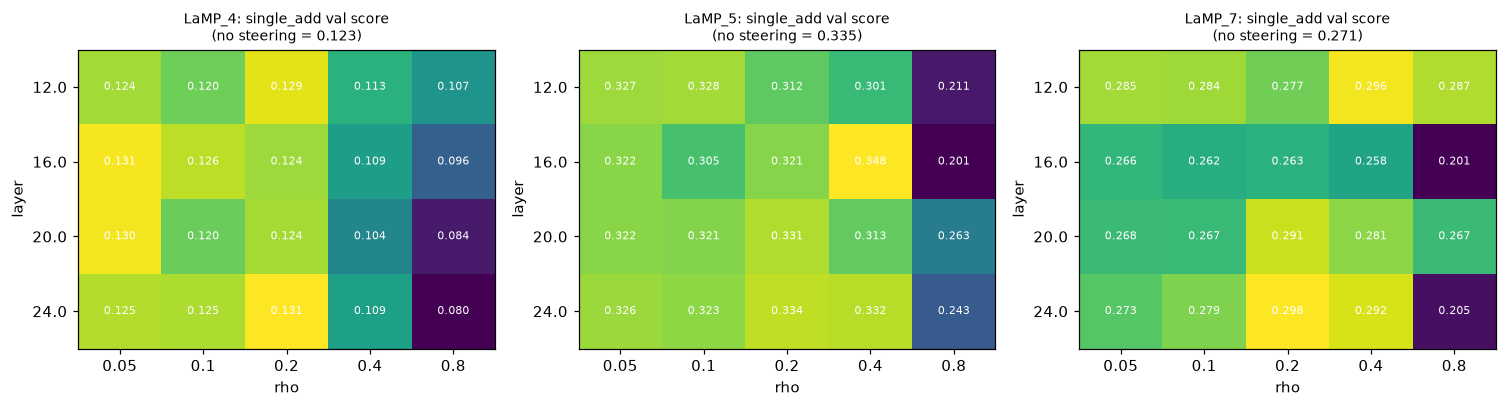

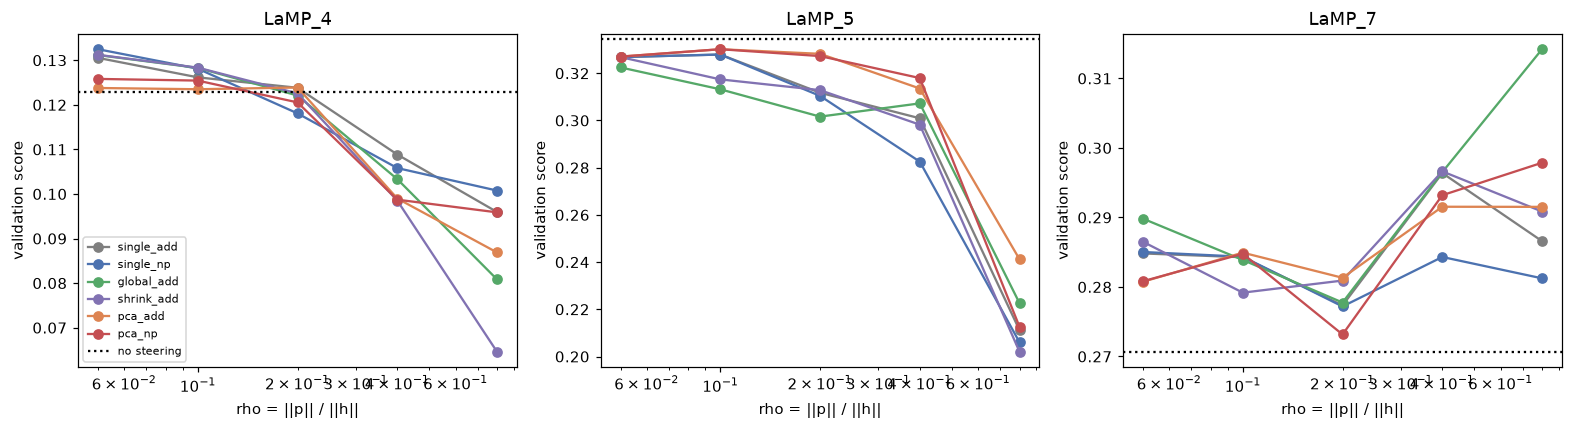

In [48]:
# Cell 5.4 — Select each method's best setting; save; diagnostics plots
long_val2 = load_long("val2", TASKS)
TUNED = select_stage2(long_val2, TUNED)
with open(CHECKPOINT_DIR / "tuned_settings.json", "w") as f:
    json.dump(TUNED, f, indent=2)
tuned_tbl = tuned_table(TUNED)
display(tuned_tbl.round(4))

# (a) stage-1 heatmap: validation score over layer x rho for the original method
fig, axes = plt.subplots(1, len(TASKS), figsize=(4.6 * len(TASKS), 3.8), squeeze=False)
for ax, task in zip(axes[0], TASKS):
    sub = long_val1[(long_val1.task == task) & (long_val1.family == "single_add") & (long_val1.pos == POS_GRID[0])]
    piv = sub.pivot_table(index="layer", columns="rho", values="score", aggfunc="mean")
    ax.imshow(piv.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f"{c:g}" for c in piv.columns])
    ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels(piv.index)
    for (i, j), v in np.ndenumerate(piv.values):
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="w", fontsize=7)
    ax.set_title(f"{task}: single_add val score\n(no steering = {TUNED[task]['base_val']:.3f})", fontsize=9)
    ax.set_xlabel("rho"); ax.set_ylabel("layer")
plt.tight_layout(); plt.savefig(CHECKPOINT_DIR / "val_heatmap.png", dpi=150); plt.show()

# (b) validation score vs rho for every family (at its tuned layer / k / kappa)
palette = {"single_add": "#7f7f7f", "single_np": "#4c72b0", "global_add": "#55a868",
           "shrink_add": "#8172b2", "pca_add": "#dd8452", "pca_np": "#c44e52"}
fig, axes = plt.subplots(1, len(TASKS), figsize=(4.8 * len(TASKS), 4), squeeze=False)
for ax, task in zip(axes[0], TASKS):
    for fam in FAMILIES:
        t = TUNED[task].get(fam)
        if not t:
            continue
        src = long_val1 if fam == "single_add" else long_val2
        s = src[(src.task == task) & (src.family == fam) & (src.layer == t["layer"]) & (src.pos == t["pos"])
                & (src.k == t["k"]) & (src.kappa == t["kappa"])].groupby("rho")["score"].mean()
        ax.plot(s.index, s.values, "o-", color=palette[fam], label=fam)
    ax.axhline(TUNED[task]["base_val"], ls=":", color="k", label="no steering")
    ax.set_xscale("log"); ax.set_xlabel("rho = ||p|| / ||h||"); ax.set_ylabel("validation score"); ax.set_title(task)
    if task == TASKS[0]: ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(CHECKPOINT_DIR / "val_rho_curves.png", dpi=150); plt.show()

In [49]:
# Cell 5.5 — TEST: base + every method at its own validation-selected setting (users never used for tuning)
for task in TASKS:
    run_experiment("test", task, test_users[task], build_test_configs(task))

test/LaMP_4: 100%|██████████| 150/150 [00:00<00:00, 2184533.33it/s]


test/LaMP_4: 0 new users this run (150 total).


test/LaMP_5: 100%|██████████| 150/150 [00:00<00:00, 197286.17it/s]


[411829] ERROR, skipping: name 'model' is not defined
test/LaMP_5: 0 new users this run (149 total).


test/LaMP_7: 100%|██████████| 150/150 [00:00<00:00, 2557502.44it/s]

test/LaMP_7: 0 new users this run (150 total).


## Part 6 — Test results

In [50]:
# Cell 6.1 — Summary table (cleaned scores) + how often steering changes the output + output length
long_test = load_long("test", TASKS)
ORDER = ["base"] + list(FAMILIES)

def summarize(long, order, ref_sv=BASE_SV):
    long = long.assign(words=long["pred"].str.split().str.len())
    g = long.groupby(["task", "config"]).agg(rougeL=("rougeL", "mean"), meteor=("meteor", "mean"),
                                             words=("words", "mean"), n=("user_id", "nunique")).reset_index()
    out = []
    for task, sub in g.groupby("task"):
        sub = sub.set_index("config")
        w = long[long.task == task].pivot(index="user_id", columns="config", values="pred")
        for cfg in [c for c in order if c in sub.index]:
            r = sub.loc[cfg]
            row = {"Task": task, "Config": cfg, "ROUGE-L": r.rougeL, "METEOR": r.meteor, "avg words": r.words,
                   "n": int(r.n), "output changed vs base %": 100 * (w[cfg] != w["base"]).mean() if "base" in w else np.nan}
            for ref, lab in [("base", "vs base"), (ref_sv, "vs StyleVector")]:
                if ref in sub.index:
                    for m, col in [("rougeL", "ROUGE-L"), ("meteor", "METEOR")]:
                        row[f"{col} Δ% {lab}"] = 100 * (r[m] - sub.loc[ref, m]) / sub.loc[ref, m]
            out.append(row)
    return pd.DataFrame(out)

summary_test = summarize(long_test, ORDER)
summary_test.round(4)

,Task,Config,ROUGE-L,METEOR,avg words,n,output changed vs base %,ROUGE-L Δ% vs base,METEOR Δ% vs base,ROUGE-L Δ% vs StyleVector,METEOR Δ% vs StyleVector
0,LaMP_4,base,0.1105,0.0933,12.2933,150,0.0000,0.0000,0.0000,-4.4460,-7.2294
1,LaMP_4,single_add,0.1156,0.1006,12.3867,150,31.3333,4.6528,7.7928,0.0000,0.0000
2,LaMP_4,single_np,0.1136,0.1001,12.0800,150,24.0000,2.8278,7.2619,-1.7439,-0.4926
3,LaMP_4,global_add,0.1097,0.0917,12.2667,150,27.3333,-0.6726,-1.7258,-5.0887,-8.8305
4,LaMP_4,shrink_add,0.1123,0.0950,12.4133,150,27.3333,1.6139,1.7491,-2.9038,-5.6067
5,LaMP_4,pca_add,0.1136,0.0981,12.2067,150,30.0000,2.7966,5.1552,-1.7737,-2.4470
6,LaMP_4,pca_np,0.1127,0.0983,12.0000,150,23.3333,2.0618,5.3166,-2.4758,-2.2972
7,LaMP_5,base,0.3240,0.3269,10.5705,149,0.0000,0.0000,0.0000,0.3509,0.7024
8,LaMP_5,single_add,0.3229,0.3246,10.5034,149,26.8456,-0.3497,-0.6975,0.0000,0.0000
9,LaMP_5,single_np,0.3199,0.3220,10.4899,149,26.8456,-1.2724,-1.5066,-0.9259,-0.8148


In [51]:
# Cell 6.2 — Paired bootstrap of per-user differences (A minus B)
def paired_bootstrap(diff, n_boot=5000, seed=0):
    diff = np.asarray(diff, dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(diff), (n_boot, len(diff)))
    lo, hi = np.percentile(diff[idx].mean(1), [2.5, 97.5])
    return diff.mean(), lo, hi

def compare(long, a, b, tasks=TASKS, score_cols=(("rougeL", "ROUGE-L"), ("meteor", "METEOR"))):
    rows = []
    for task in tasks:
        sub = long[long["task"] == task]
        for metric, name in score_cols:
            w = sub.pivot(index="user_id", columns="config", values=metric)
            if a not in w or b not in w: continue
            d = (w[a] - w[b]).dropna().values
            if len(d) < 2: continue
            mean, lo, hi = paired_bootstrap(d)
            rows.append({"Task": task, "Metric": name, "A": a, "B": b, "mean diff (A-B)": mean,
                         "95% CI lo": lo, "95% CI hi": hi, "A wins %": 100 * (d > 0).mean(),
                         "ties %": 100 * (d == 0).mean(), "n": len(d),
                         "verdict": "A better" if lo > 0 else ("A worse" if hi < 0 else "inconclusive")})
    return pd.DataFrame(rows)

PAIRS = [("single_add", "base",       "Does the reproduced StyleVector help at all?"),
         ("global_add", "single_add", "Is a NON-personalised global vector as good as the user vector? (A better => gain is not personal)"),
         ("single_add", "global_add", "Does the user vector beat the global vector? (A better => genuine personalisation)"),
         ("shrink_add", "single_add", "Does shrinking the user vector toward the global mean help?"),
         ("shrink_add", "global_add", "Does the shrunk vector keep anything personal beyond the global one?"),
         ("pca_add",    "single_add", "Multi-component (PCA) alone vs. original"),
         ("single_np",  "single_add", "Norm preservation alone vs. original"),
         ("pca_np",     "single_add", "OUR FULL METHOD (PCA + norm-preserving) vs. original"),
         ("pca_np",     "pca_add",    "Norm preservation on top of PCA")]
comparisons = pd.concat([compare(long_test, a, b).assign(question=q) for a, b, q in PAIRS], ignore_index=True)
comparisons.round(4)

,Task,Metric,A,B,mean diff (A-B),95% CI lo,95% CI hi,A wins %,ties %,n,verdict,question
0,LaMP_4,ROUGE-L,single_add,base,0.0051,-0.0033,0.0160,10.0000,76.6667,150,inconclusive,Does the reproduced StyleVector help at all?
1,LaMP_4,METEOR,single_add,base,0.0073,-0.0028,0.0212,12.0000,74.0000,150,inconclusive,Does the reproduced StyleVector help at all?
2,LaMP_5,ROUGE-L,single_add,base,-0.0011,-0.0117,0.0101,10.7383,80.5369,149,inconclusive,Does the reproduced StyleVector help at all?
3,LaMP_5,METEOR,single_add,base,-0.0023,-0.0149,0.0097,10.0671,79.1946,149,inconclusive,Does the reproduced StyleVector help at all?
4,LaMP_7,ROUGE-L,single_add,base,0.0041,-0.0057,0.0136,19.3333,68.0000,150,inconclusive,Does the reproduced StyleVector help at all?
5,LaMP_7,METEOR,single_add,base,0.0107,0.0007,0.0209,22.6667,65.3333,150,A better,Does the reproduced StyleVector help at all?
6,LaMP_4,ROUGE-L,global_add,single_add,-0.0059,-0.0160,0.0011,6.6667,88.0000,150,inconclusive,Is a NON-personalised global vector as good as...
7,LaMP_4,METEOR,global_add,single_add,-0.0089,-0.0226,0.0006,6.0000,86.6667,150,inconclusive,Is a NON-personalised global vector as good as...
8,LaMP_5,ROUGE-L,global_add,single_add,-0.0012,-0.0095,0.0075,4.0268,91.9463,149,inconclusive,Is a NON-personalised global vector as good as...
9,LaMP_5,METEOR,global_add,single_add,-0.0019,-0.0107,0.0063,4.6980,91.9463,149,inconclusive,Is a NON-personalised global vector as good as...


In [52]:
# Cell 6.3 — Plain-language verdicts
for a, b, q in PAIRS:
    v = compare(long_test, a, b)
    print(f"\n{q}\n  ({a} minus {b}; paired bootstrap 95% CI, test users only)")
    for task in TASKS:
        parts = []
        for metric in ["ROUGE-L", "METEOR"]:
            r = v[(v.Task == task) & (v.Metric == metric)]
            if len(r):
                r = r.iloc[0]
                parts.append(f"{metric} {r['mean diff (A-B)']:+.4f} [{r['95% CI lo']:+.4f},{r['95% CI hi']:+.4f}] {r['verdict']}")
        print(f"  {task:7s} " + " | ".join(parts))


Does the reproduced StyleVector help at all?
  (single_add minus base; paired bootstrap 95% CI, test users only)
  LaMP_4  ROUGE-L +0.0051 [-0.0033,+0.0160] inconclusive | METEOR +0.0073 [-0.0028,+0.0212] inconclusive
  LaMP_5  ROUGE-L -0.0011 [-0.0117,+0.0101] inconclusive | METEOR -0.0023 [-0.0149,+0.0097] inconclusive
  LaMP_7  ROUGE-L +0.0041 [-0.0057,+0.0136] inconclusive | METEOR +0.0107 [+0.0007,+0.0209] A better

Is a NON-personalised global vector as good as the user vector? (A better => gain is not personal)
  (global_add minus single_add; paired bootstrap 95% CI, test users only)
  LaMP_4  ROUGE-L -0.0059 [-0.0160,+0.0011] inconclusive | METEOR -0.0089 [-0.0226,+0.0006] inconclusive
  LaMP_5  ROUGE-L -0.0012 [-0.0095,+0.0075] inconclusive | METEOR -0.0019 [-0.0107,+0.0063] inconclusive
  LaMP_7  ROUGE-L +0.0031 [-0.0067,+0.0135] inconclusive | METEOR +0.0050 [-0.0034,+0.0141] inconclusive

Does the user vector beat the global vector? (A better => genuine personalisation)
  

In [53]:
# Cell 6.4 — 2x2 ablation (every cell tuned separately on validation users) + the settings used
def ablation_2x2(long, metric):
    rows = []
    for task, sub in long.groupby("task"):
        m = sub.groupby("config")[metric].mean()
        for label, stem in [("single vector (mean-diff)", "single"), ("multi-component (PCA, tuned k)", "pca")]:
            rows.append({"Task": task, "Style representation": label,
                         "additive": m.get(f"{stem}_add", np.nan), "norm-preserving": m.get(f"{stem}_np", np.nan),
                         "global vector (control)": m.get("global_add", np.nan) if stem == "single" else np.nan,
                         "non-personalised": m.get("base", np.nan)})
    return pd.DataFrame(rows).set_index(["Task", "Style representation"])

for metric, name in [("rougeL", "ROUGE-L"), ("meteor", "METEOR")]:
    print(f"\n=== 2x2 ablation — {name} (test users) ===")
    display(ablation_2x2(long_test, metric).round(4))
print("\nSettings used by each method:")
display(tuned_tbl[["Task", "Method", "layer", "rho", "k", "kappa", "pos"]])


=== 2x2 ablation — ROUGE-L (test users) ===


additive  norm-preserving  \
Task   Style representation                                        
LaMP_4 single vector (mean-diff)         0.1156           0.1136   
       multi-component (PCA, tuned k)    0.1136           0.1127   
LaMP_5 single vector (mean-diff)         0.3229           0.3199   
       multi-component (PCA, tuned k)    0.3218           0.3213   
LaMP_7 single vector (mean-diff)         0.3016           0.2978   
       multi-component (PCA, tuned k)    0.3042           0.3035   

                                       global vector (control)  \
Task   Style representation                                      
LaMP_4 single vector (mean-diff)                        0.1097   
       multi-component (PCA, tuned k)                      NaN   
LaMP_5 single vector (mean-diff)                        0.3216   
       multi-component (PCA, tuned k)                      NaN   
LaMP_7 single vector (mean-diff)                        0.3047   
       multi-component (PCA, tuned k)                      NaN   

                                       non-personalised  
Task   Style representation                              
LaMP_4 single vector (mean-diff)                 0.1105  
       multi-component (PCA, tuned k)            0.1105  
LaMP_5 single vector (mean-diff)                 0.3240  
       multi-component (PCA, tuned k)            0.3240  
LaMP_7 single vector (mean-diff)                 0.2975  
       multi-component (PCA, tuned k)            0.2975


=== 2x2 ablation — METEOR (test users) ===


additive  norm-preserving  \
Task   Style representation                                        
LaMP_4 single vector (mean-diff)         0.1006           0.1001   
       multi-component (PCA, tuned k)    0.0981           0.0983   
LaMP_5 single vector (mean-diff)         0.3246           0.3220   
       multi-component (PCA, tuned k)    0.3252           0.3235   
LaMP_7 single vector (mean-diff)         0.2746           0.2716   
       multi-component (PCA, tuned k)    0.2754           0.2759   

                                       global vector (control)  \
Task   Style representation                                      
LaMP_4 single vector (mean-diff)                        0.0917   
       multi-component (PCA, tuned k)                      NaN   
LaMP_5 single vector (mean-diff)                        0.3228   
       multi-component (PCA, tuned k)                      NaN   
LaMP_7 single vector (mean-diff)                        0.2796   
       multi-component (PCA, tuned k)                      NaN   

                                       non-personalised  
Task   Style representation                              
LaMP_4 single vector (mean-diff)                 0.0933  
       multi-component (PCA, tuned k)            0.0933  
LaMP_5 single vector (mean-diff)                 0.3269  
       multi-component (PCA, tuned k)            0.3269  
LaMP_7 single vector (mean-diff)                 0.2640  
       multi-component (PCA, tuned k)            0.2640


Settings used by each method:


,Task,Method,layer,rho,k,kappa,pos
0,LaMP_4,single_add,16,0.05,1,0.0,last
1,LaMP_4,single_np,16,0.05,1,0.0,last
2,LaMP_4,global_add,16,0.05,1,0.0,last
3,LaMP_4,shrink_add,16,0.05,1,10.0,last
4,LaMP_4,pca_add,16,0.05,3,0.0,last
5,LaMP_4,pca_np,16,0.05,3,0.0,last
6,LaMP_5,single_add,12,0.05,1,0.0,last
7,LaMP_5,single_np,12,0.05,1,0.0,last
8,LaMP_5,global_add,12,0.05,1,0.0,last
9,LaMP_5,shrink_add,12,0.05,1,10.0,last


In [54]:
# Cell 6.5 — Effect of output cleaning + length mismatch (raw vs cleaned scores, same outputs)
rows = []
for task in TASKS:
    sub = long_test[long_test.task == task]
    gold_words = sub.drop_duplicates("user_id")["gold"].str.split().str.len().mean()
    m = sub.groupby("config")[["rougeL", "meteor", "rougeL_raw", "meteor_raw"]].mean()
    for cfg in ORDER:
        if cfg in m.index:
            s = sub[sub.config == cfg]
            rows.append({"Task": task, "Config": cfg, "ROUGE-L raw": m.loc[cfg, "rougeL_raw"], "ROUGE-L cleaned": m.loc[cfg, "rougeL"],
                         "METEOR raw": m.loc[cfg, "meteor_raw"], "METEOR cleaned": m.loc[cfg, "meteor"],
                         "words raw": s["raw"].str.split().str.len().mean(), "words cleaned": s["pred"].str.split().str.len().mean(),
                         "words gold": gold_words})
pd.DataFrame(rows).round(4)

,Task,Config,ROUGE-L raw,ROUGE-L cleaned,METEOR raw,METEOR cleaned,words raw,words cleaned,words gold
0,LaMP_4,base,0.0941,0.1105,0.1129,0.0933,23.0933,12.2933,9.2933
1,LaMP_4,single_add,0.0947,0.1156,0.1136,0.1006,23.2267,12.3867,9.2933
2,LaMP_4,single_np,0.0932,0.1136,0.1129,0.1001,23.0267,12.0800,9.2933
3,LaMP_4,global_add,0.0946,0.1097,0.1138,0.0917,23.1733,12.2667,9.2933
4,LaMP_4,shrink_add,0.0953,0.1123,0.1141,0.0950,23.2333,12.4133,9.2933
5,LaMP_4,pca_add,0.0958,0.1136,0.1138,0.0981,23.1867,12.2067,9.2933
6,LaMP_4,pca_np,0.0949,0.1127,0.1125,0.0983,23.0600,12.0000,9.2933
7,LaMP_5,base,0.2152,0.3240,0.3167,0.3269,24.4564,10.5705,9.0201
8,LaMP_5,single_add,0.2123,0.3229,0.3139,0.3246,24.4899,10.5034,9.0201
9,LaMP_5,single_np,0.2109,0.3199,0.3113,0.3220,24.4832,10.4899,9.0201


In [55]:
# Cell 6.6 — How personal is the user vector? (cached deltas of the test users; no model needed)
rows, comp = [], []
for task in TASKS:
    L = TUNED[task]["single_add"]["layer"]
    S, N = GLOBAL[task][L]
    gvec = S / N
    for uid in test_users[task]:
        D = safe_load_deltas(delta_cache_path(task, uid))
        if D is None:
            continue
        D = D[L]
        mu = D.mean(0)
        rows.append({"task": task, "cos(user mean, global mean)": F.cosine_similarity(mu, gvec, dim=0).item(),
                     "||user mean|| / ||global mean||": (mu.norm() / gvec.norm()).item(), "n history": D.shape[0]})
        if D.shape[0] >= 5:
            _, sv, _ = torch.linalg.svd(D, full_matrices=False)
            V, _ = style_components(D, 5)
            share = (sv ** 2 / (sv ** 2).sum())[:5]
            cv = F.cosine_similarity(V, mu[None, :], dim=1)
            for j in range(5):
                comp.append({"task": task, "component": j + 1, "energy share": share[j].item(), "cos(v_j, user mean)": cv[j].item()})
pers = pd.DataFrame(rows)
print("If cos(user mean, global mean) is close to 1, the 'personal' vector is mostly a task-wide style shift.")
display(pers.groupby("task").mean().round(3))
display(pd.DataFrame(comp).groupby(["task", "component"]).mean().round(3))

/tmp/ipykernel_163691/4181944788.py:31: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  blob = torch.load(path, map_location="cpu")


If cos(user mean, global mean) is close to 1, the 'personal' vector is mostly a task-wide style shift.


,"cos(user mean, global mean)",||user mean|| / ||global mean||,n history
task,,,
LaMP_4,0.562,0.821,24.907
LaMP_5,0.652,1.546,30.000
LaMP_7,0.950,1.051,12.733


energy share  cos(v_j, user mean)
task   component                                   
LaMP_4 1                 0.624                0.935
       2                 0.042                0.161
       3                 0.035                0.078
       4                 0.032                0.057
       5                 0.029                0.044
LaMP_5 1                 0.178                0.917
       2                 0.077                0.227
       3                 0.060                0.119
       4                 0.050                0.079
       5                 0.045                0.069
LaMP_7 1                 0.656                1.000
       2                 0.072                0.010
       3                 0.049                0.005
       4                 0.040                0.003
       5                 0.034                0.002

In [56]:
# Cell 6.7 — Qualitative cases: gold vs. base vs. original vs. global vs. shrinkage vs. our full method
N_CASES = 4
for task in TASKS:
    print(f"\n{'='*25} {task} — first test users where our full method differs from StyleVector {'='*25}")
    sub = long_test[long_test.task == task]
    w = sub.pivot(index="user_id", columns="config", values="pred")
    gold = sub.drop_duplicates("user_id").set_index("user_id")["gold"]
    for uid, row in w[w[FULL_NAME] != w[BASE_SV]].head(N_CASES).iterrows():
        print(f"\n[user {uid}]")
        print(f"  gold        : {gold[uid][:90]!r}")
        for c in ["base", "single_add", "global_add", "shrink_add", FULL_NAME]:
            if c in row:
                print(f"  {c:<11s} : {row[c][:90]!r}")


========================= LaMP_4 — first test users where our full method differs from StyleVector =========================

[user 311028]
  gold        : 'Paul Ryan Pledges 9/11 Bill Is All But Done'
  base        : '1. "Two Hurdles Remain: Will Bill Make It to Vote and How to Pay for It?'
  single_add  : '1. "Two Hurdles Remain: Will Bill Reach Vote and How to Pay for It?'
  global_add  : '1. "Two Hurdles Remain: Will Bill Reach Vote and How to Pay for It?'
  shrink_add  : '1. "Two Hurdles Remain: Will Bill Reach Vote and How to Pay for It?'
  pca_np      : '1. "Two Hurdles Remain: Will Bill Make It to Vote and How to Pay for It?'

[user 311053]
  gold        : "Boehner's Departure Won't Make Congress Better, But It Could Make It Worse"
  base        : '1. "Speaker\'s Resignation Rocks House of Representatives'
  single_add  : '1. "Speaker\'s Resignation Rocks House of Representatives'
  global_add  : '1. "Speaker\'s Resignation Rocks House of Representatives'
  shrink_add  : '1. "

In [57]:
# Cell 6.8 — Raw comparison with the paper's Table 2 (no adjustments). Absolute numbers differ by design
# (model size/precision, M_g, user sample, cleaning); this only checks the direction of the effect.
PAPER = {"LaMP_4": (0.0398, 0.0790, 0.0411, 0.0809), "LaMP_5": (0.1086, 0.2337, 0.1366, 0.2575),
         "LaMP_7": (0.2506, 0.2588, 0.2827, 0.3042)}      # (R-L base, METEOR base, R-L StyleVector, METEOR StyleVector)
rows = []
for task in TASKS:
    m = long_test[long_test.task == task].groupby("config")[["rougeL", "meteor"]].mean()
    pb_r, pb_m, ps_r, ps_m = PAPER[task]
    for metric, name, pb, ps in [("rougeL", "ROUGE-L", pb_r, ps_r), ("meteor", "METEOR", pb_m, ps_m)]:
        row = {"Task": task, "Metric": name, "Paper Δ%": 100 * (ps - pb) / pb}
        for fam in ["single_add", "global_add", "shrink_add", FULL_NAME]:
            if fam in m.index:
                row[f"{fam} Δ%"] = 100 * (m.loc[fam, metric] - m.loc["base", metric]) / m.loc["base", metric]
        rows.append(row)
pd.DataFrame(rows).round(2)

,Task,Metric,Paper Δ%,single_add Δ%,global_add Δ%,shrink_add Δ%,pca_np Δ%
0,LaMP_4,ROUGE-L,3.27,4.65,-0.67,1.61,2.06
1,LaMP_4,METEOR,2.41,7.79,-1.73,1.75,5.32
2,LaMP_5,ROUGE-L,25.78,-0.35,-0.73,-0.69,-0.85
3,LaMP_5,METEOR,10.18,-0.70,-1.27,-1.46,-1.03
4,LaMP_7,ROUGE-L,12.81,1.39,2.44,1.96,2.04
5,LaMP_7,METEOR,17.54,4.05,5.92,5.05,4.50


## Part 7 — Save everything

In [58]:
long_val1.to_csv(CHECKPOINT_DIR / "val1_long.csv", index=False)
long_val2.to_csv(CHECKPOINT_DIR / "val2_long.csv", index=False)
long_test.to_csv(CHECKPOINT_DIR / "test_long.csv", index=False)
summary_test.to_csv(CHECKPOINT_DIR / "summary_test.csv", index=False)
comparisons.to_csv(CHECKPOINT_DIR / "paired_comparisons_test.csv", index=False)
tuned_tbl.to_csv(CHECKPOINT_DIR / "tuned_settings_table.csv", index=False)
pers.to_csv(CHECKPOINT_DIR / "personalisation_diagnostic.csv", index=False)
for metric in ["rougeL", "meteor"]:
    ablation_2x2(long_test, metric).to_csv(CHECKPOINT_DIR / f"ablation_2x2_{metric}.csv")
print("Saved to:", CHECKPOINT_DIR.resolve())
for p in sorted(CHECKPOINT_DIR.glob("*.csv")) + sorted(CHECKPOINT_DIR.glob("*.png")) + sorted(CHECKPOINT_DIR.glob("*.json")):
    print(" -", p.name)

Saved to: /home/user/stylevector_project/checkpoints_v2
 - ablation_2x2_meteor.csv
 - ablation_2x2_rougeL.csv
 - paired_comparisons_test.csv
 - personalisation_diagnostic.csv
 - summary_test.csv
 - test_long.csv
 - tuned_settings_table.csv
 - val1_long.csv
 - val2_long.csv
 - val_heatmap.png
 - val_rho_curves.png
 - settings.json
 - tuned_settings.json


In [59]:
del model
if gen_model is not None:
    del gen_model
torch.cuda.empty_cache()

NameError: name 'model' is not defined